## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Juan Jose Garcia Herrera" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**
Una empresa necesita optimizar dos procesos operativos dentro de un único entorno de ejecucion(Python) administrar tareas tecnicas segun la prioridad y contectar varios disposotivos usando la menor cantidad de cables posibles.


## 2) Requerimientos **[2 pts]**

**RF1:** Contruir una cola de prioridad maxima mediante un arreglo estructurado como Max-Heap, implementando manualmente las funciones.

**RF2:** Vizualizar el estado inicial de las tareas, el arreglo resultante tras contruir el Max-Heap y su representacion jerarquica en forma d earbol.

**RF3:** Permitir la insercion de la tarea reordenando hacia arriba para conservar la prioridad

**RF4:** Graficar la ubicacion espacial de los disposotivos y calcular automoaticamente las aristas

**RF5:** Ejecutar el algoritmo de kruskal para obtener las conexiones del mst y calcular la longitud total del cable.

**RF6:** Generar la grafica final que muestre los nodos, las 5 aristas del MST, el pedo de cada conexion y el total de cable utilizado.

**RNF1:** Todo el proceso debe ejecutarde de forma ordenada y automatica.
RNF2 El codigo debe mantener yba estructura modular con funciones para facilitar la verificacion.



## 3) Historias de usuario **[2 pts]**
HU1: Como ingeniero de soporte tecnico, quiero organizar las tareas pendientes en un Max-Heap segun su nivel de urgencia, para identifiar y atender unmediatamente las incidencias mas criticas

HU2: Como coordinador de operaciones, quiero extraer las tareas de mayor prioridad conforme se resuelven e insertar alertas en tirmpo real para asegurar que el orden de atencion se mantenga actualizado.

HU3: Como arquitecto de insfraestructuras, quiero calcular las distancias entre los deispositivos y obtener el arbol de expansion minima con el algoritmo de kruskal, reduciendo el costo al minimo del cableado.


## 4) Diagramas de flujo **[5 pts]**
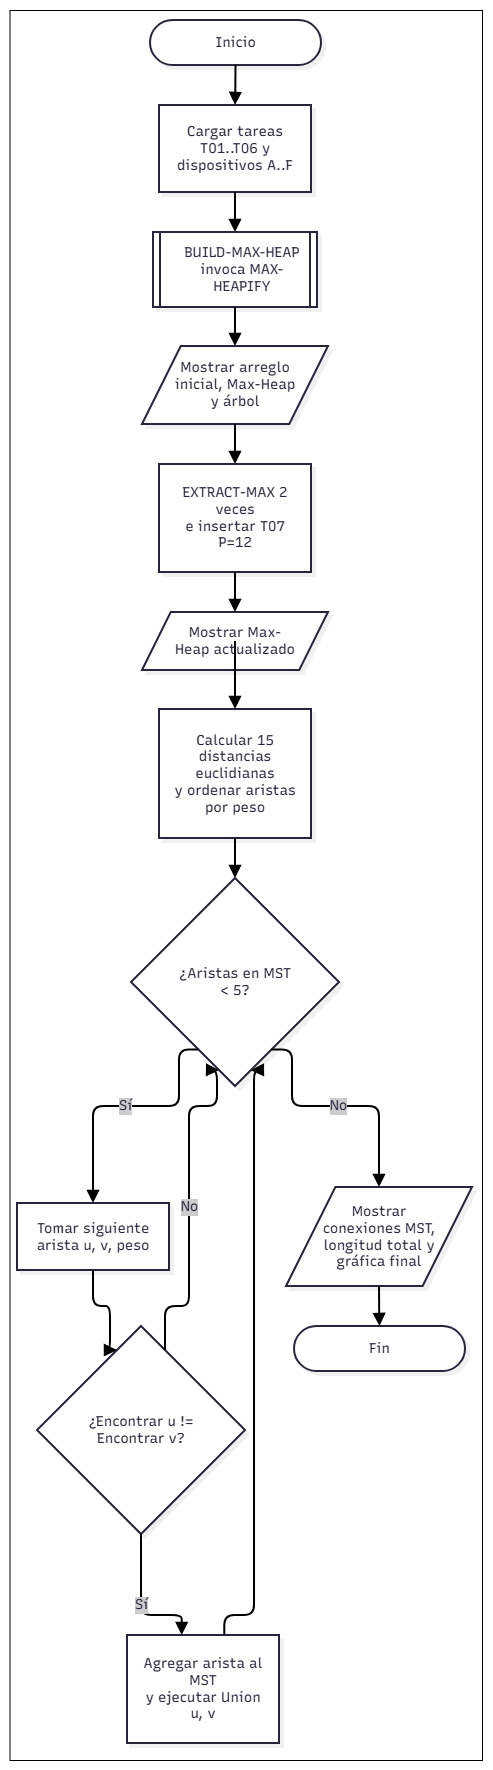

## 6) Analisis de complejidad
**Justificación:** En la Cola de Prioridad (Max-Heap), al estructurarse como un árbol binario completo de altura logarítmica, las operaciones de inserción y extracción realizan como máximo un intercambio por nivel, mientras que la construcción inicial ajusta únicamente la mitad interna de los nodos en tiempo lineal.

Por su parte, en el algoritmo de Kruskal para V dispositivos y E = V(V - 1) / 2 conexiones posibles, el tiempo de ejecución está dominado por el ordenamiento inicial de las aristas, dado que la detección de ciclos mediante conjuntos disjuntos (Union-Find con compresión de caminos) opera en tiempo prácticamente constante.

**Mejor y peor caso:** En las operaciones del Max-Heap, el mejor caso es Omega(1) cuando el elemento insertado o reubicado ya cumple la propiedad de orden respecto a sus vecinos inmediatos sin requerir desplazamientos, mientras que el peor caso es O(log n) cuando debe recorrer toda la altura del árbol.

En el algoritmo de Kruskal, tanto el mejor caso O(n log n) como el peor caso O(n log n) —equivalente a O(n^2 log n) en grafos completos— están acotados por el ordenamiento de las aristas, diferenciándose únicamente en que en el mejor caso las primeras V - 1 aristas no generan ciclos y detienen el bucle de selección de inmediato, mientras que en el peor caso se evalúa casi la totalidad de las aristas descartando ciclos antes de completar el árbol.
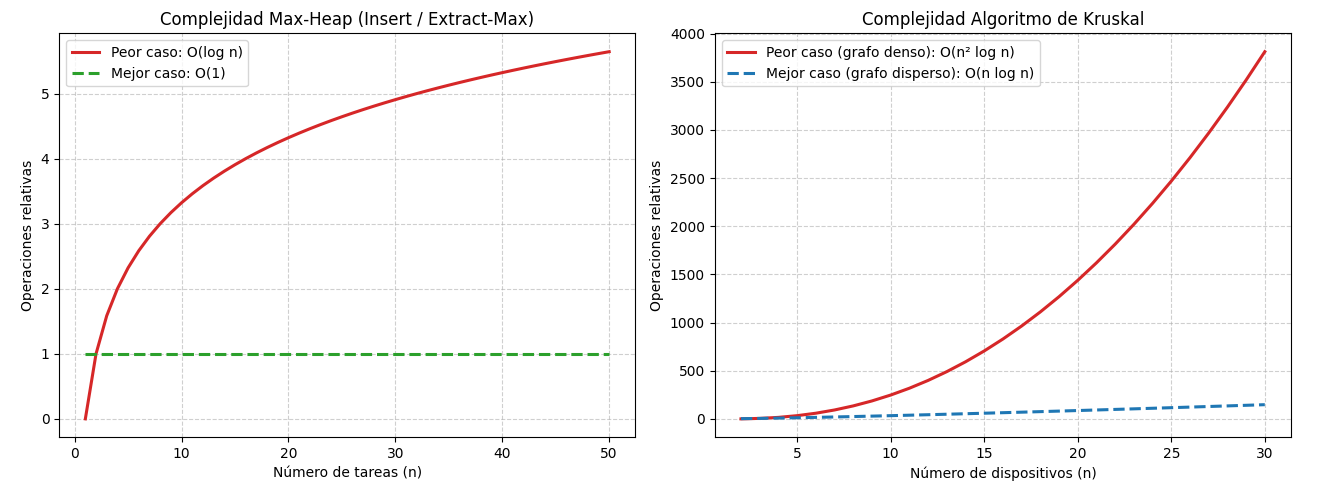

## 6) Código funcional **[15 pts]**



=== PUNTO 1: CONSTRUCCIÓN DEL MAX-HEAP ===
Arreglo inicial:
 - T01 (Configurar servidor - P:6)
 - T02 (Reparar sensor - P:10)
 - T03 (Actualizar software - P:4)
 - T04 (Revisar cámara - P:8)
 - T05 (Generar respaldo - P:3)
 - T06 (Configurar alarma - P:7)

Max-Heap resultante:
 - T02 (Reparar sensor - P:10)
 - T04 (Revisar cámara - P:8)
 - T06 (Configurar alarma - P:7)
 - T01 (Configurar servidor - P:6)
 - T05 (Generar respaldo - P:3)
 - T03 (Actualizar software - P:4)

Árbol correspondiente al Heap:
Nivel 0: [T02: P=10]
Nivel 1: [T04: P=8]   [T06: P=7]
Nivel 2: [T01: P=6]   [T05: P=3]   [T03: P=4]

=== PUNTO 2: PROCESAMIENTO E INSERCIÓN DE TAREAS ===

Extracción 1 -> Tarea procesada: T02 - Reparar sensor (Prioridad: 10)
Heap resultante:
 - T04 (Revisar cámara - P:8)
 - T01 (Configurar servidor - P:6)
 - T06 (Configurar alarma - P:7)
 - T03 (Actualizar software - P:4)
 - T05 (Generar respaldo - P:3)

Extracción 2 -> Tarea procesada: T04 - Revisar cámara (Prioridad: 8)
Heap resultante:


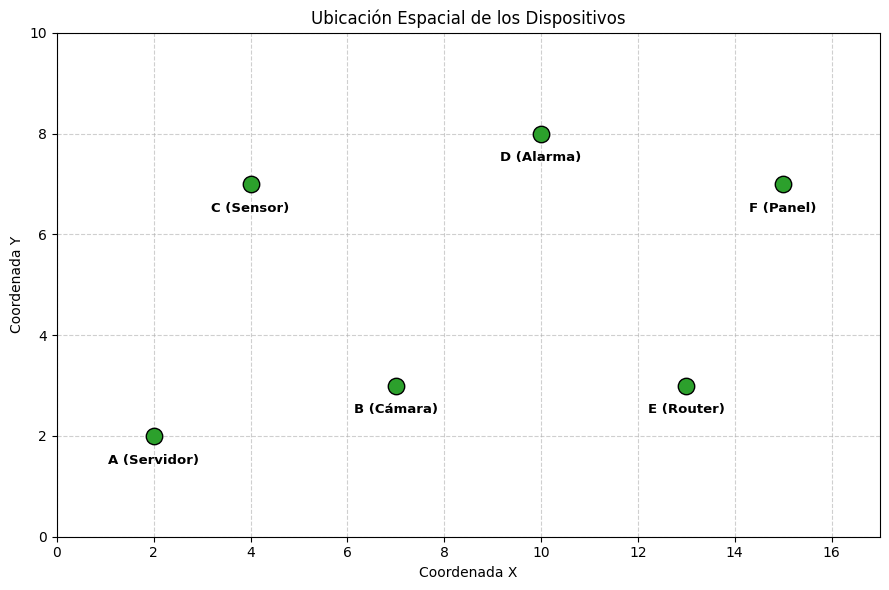


=== PUNTO 4: ÁRBOL DE EXPANSIÓN MÍNIMA (KRUSKAL) ===
Conexiones seleccionadas:
E - F: 4.47
B - C: 5.00
A - B: 5.10
D - F: 5.10
B - D: 5.83
Longitud total de cable: 25.50

=== PUNTO 5: VISUALIZACIÓN FINAL DEL MST ===


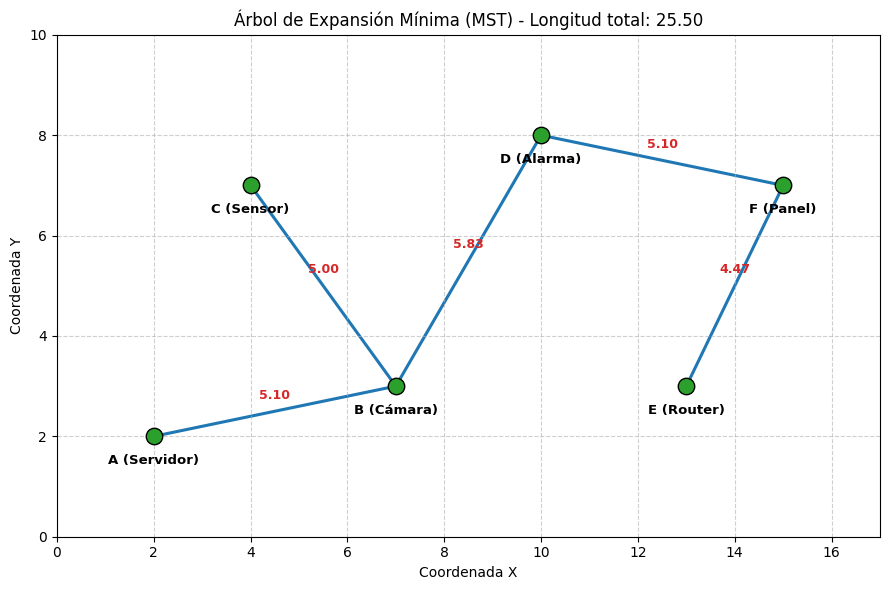

In [5]:
import math
import matplotlib.pyplot as plt

def max_heapify(heap, n, i):
   mayor = i
   izquierda = 2 * i + 1
   derecha = 2 * i + 2
   if izquierda < n and heap[izquierda]["prioridad"] > heap[mayor]["prioridad"]:
       mayor = izquierda
   if derecha < n and heap[derecha]["prioridad"] > heap[mayor]["prioridad"]:
       mayor = derecha
   if mayor != i:
       heap[i], heap[mayor] = heap[mayor], heap[i]
       max_heapify(heap, n, mayor)

def build_max_heap(tareas):
   heap = [tarea.copy() for tarea in tareas]
   n = len(heap)
   for i in range(n // 2 - 1, -1, -1):
       max_heapify(heap, n, i)
   return heap

def extract_max(heap):
   if not heap:
       return None
   if len(heap) == 1:
       return heap.pop()
   maximo = heap[0]
   heap[0] = heap.pop()
   max_heapify(heap, len(heap), 0)
   return maximo

def insert_max_heap(heap, nueva_tarea):
   heap.append(nueva_tarea.copy())
   i = len(heap) - 1
   while i > 0:
       padre = (i - 1) // 2
       if heap[i]["prioridad"] > heap[padre]["prioridad"]:
           heap[i], heap[padre] = heap[padre], heap[i]
           i = padre
       else:
           break

def formatear_heap(heap):
   return [f"{t['codigo']} ({t['tarea']} - P:{t['prioridad']})" for t in heap]

def imprimir_arbol_heap(heap):
   n = len(heap)
   if n == 0:
       print("Heap vacío.")
       return
   niveles = math.floor(math.log2(n)) + 1
   indice = 0
   for nivel in range(niveles):
       cantidad = 2 ** nivel
       elementos = []
       for _ in range(cantidad):
           if indice < n:
               t = heap[indice]
               elementos.append(f"[{t['codigo']}: P={t['prioridad']}]")
               indice += 1
       print(f"Nivel {nivel}: " + "   ".join(elementos))

def calcular_distancia(d1, d2):
   return math.sqrt((d2["x"] - d1["x"]) ** 2 + (d2["y"] - d1["y"]) ** 2)

def generar_aristas(dispositivos):
   aristas = []
   n = len(dispositivos)
   for i in range(n):
       for j in range(i + 1, n):
           dist = calcular_distancia(dispositivos[i], dispositivos[j])
           aristas.append((dispositivos[i]["id"], dispositivos[j]["id"], dist))
   return aristas

def find_set(padre, nodo):
   if padre[nodo] != nodo:
       padre[nodo] = find_set(padre, padre[nodo])
   return padre[nodo]

def union_sets(padre, rango, u, v):
   raiz_u = find_set(padre, u)
   raiz_v = find_set(padre, v)
   if raiz_u != raiz_v:
       if rango[raiz_u] < rango[raiz_v]:
           padre[raiz_u] = raiz_v
       elif rango[raiz_u] > rango[raiz_v]:
           padre[raiz_v] = raiz_u
       else:
           padre[raiz_v] = raiz_u
           rango[raiz_u] += 1
       return True
   return False

def kruskal_mst(dispositivos):
   aristas = generar_aristas(dispositivos)
   aristas_ordenadas = sorted(aristas, key=lambda x: x[2])
   padre = {d["id"]: d["id"] for d in dispositivos}
   rango = {d["id"]: 0 for d in dispositivos}
   mst = []
   costo_total = 0.0
   for u, v, peso in aristas_ordenadas:
       if union_sets(padre, rango, u, v):
           mst.append((u, v, peso))
           costo_total += peso
           if len(mst) == len(dispositivos) - 1:
               break
   return mst, costo_total

def graficar_dispositivos(dispositivos, mst=None, costo_total=0.0):
   plt.figure(figsize=(9, 6))
   coords = {d["id"]: (d["x"], d["y"], d["nombre"]) for d in dispositivos}
   if mst:
       for u, v, peso in mst:
           x1, y1, _ = coords[u]
           x2, y2, _ = coords[v]
           plt.plot([x1, x2], [y1, y2], color="#1f77b4", linewidth=2.2, zorder=1)
           mx, my = (x1 + x2) / 2, (y1 + y2) / 2
           plt.text(
               mx,
               my + 0.25,
               f"{peso:.2f}",
               color="#d62728",
               fontsize=9,
               fontweight="bold",
               ha="center",
           )
   for d in dispositivos:
       plt.scatter(d["x"], d["y"], color="#2ca02c", s=140, zorder=2, edgecolors="black")
       plt.text(
           d["x"],
           d["y"] - 0.55,
           f"{d['id']} ({d['nombre']})",
           fontsize=9.5,
           ha="center",
           fontweight="bold",
       )
   if mst:
       plt.title(f"Árbol de Expansión Mínima (MST) - Longitud total: {costo_total:.2f}")
   else:
       plt.title("Ubicación Espacial de los Dispositivos")
   plt.xlabel("Coordenada X")
   plt.ylabel("Coordenada Y")
   plt.xlim(0, 17)
   plt.ylim(0, 10)
   plt.grid(True, linestyle="--", alpha=0.6)
   plt.tight_layout()
   plt.show()

tareas_iniciales = [
   {"codigo": "T01", "tarea": "Configurar servidor", "prioridad": 6},
   {"codigo": "T02", "tarea": "Reparar sensor", "prioridad": 10},
   {"codigo": "T03", "tarea": "Actualizar software", "prioridad": 4},
   {"codigo": "T04", "tarea": "Revisar cámara", "prioridad": 8},
   {"codigo": "T05", "tarea": "Generar respaldo", "prioridad": 3},
   {"codigo": "T06", "tarea": "Configurar alarma", "prioridad": 7},
]
print("=== PUNTO 1: CONSTRUCCIÓN DEL MAX-HEAP ===")
print("Arreglo inicial:")
for item in formatear_heap(tareas_iniciales):
   print(" -", item)
heap_tareas = build_max_heap(tareas_iniciales)
print("\nMax-Heap resultante:")
for item in formatear_heap(heap_tareas):
   print(" -", item)
print("\nÁrbol correspondiente al Heap:")
imprimir_arbol_heap(heap_tareas)
print("\n=== PUNTO 2: PROCESAMIENTO E INSERCIÓN DE TAREAS ===")
for paso in range(1, 3):
   atendida = extract_max(heap_tareas)
   print(f"\nExtracción {paso} -> Tarea procesada: {atendida['codigo']} - {atendida['tarea']} (Prioridad: {atendida['prioridad']})")
   print("Heap resultante:")
   for item in formatear_heap(heap_tareas):
       print(" -", item)
nueva_tarea = {"codigo": "T07", "tarea": "Falla en sistema contra incendios", "prioridad": 12}
insert_max_heap(heap_tareas, nueva_tarea)
print("\nDespués de insertar T07 (Prioridad 12):")
for item in formatear_heap(heap_tareas):
   print(" -", item)
print("\nÁrbol actualizado tras inserción:")
imprimir_arbol_heap(heap_tareas)
dispositivos = [
   {"nombre": "Servidor", "id": "A", "x": 2, "y": 2},
   {"nombre": "Cámara", "id": "B", "x": 7, "y": 3},
   {"nombre": "Sensor", "id": "C", "x": 4, "y": 7},
   {"nombre": "Alarma", "id": "D", "x": 10, "y": 8},
   {"nombre": "Router", "id": "E", "x": 13, "y": 3},
   {"nombre": "Panel", "id": "F", "x": 15, "y": 7},
]
print("\n=== PUNTO 3: UBICACIÓN DE DISPOSITIVOS ===")
graficar_dispositivos(dispositivos)
print("\n=== PUNTO 4: ÁRBOL DE EXPANSIÓN MÍNIMA (KRUSKAL) ===")
mst_resultado, longitud_total = kruskal_mst(dispositivos)
print("Conexiones seleccionadas:")
for u, v, peso in mst_resultado:
   print(f"{u} - {v}: {peso:.2f}")
print(f"Longitud total de cable: {longitud_total:.2f}")
print("\n=== PUNTO 5: VISUALIZACIÓN FINAL DEL MST ===")
graficar_dispositivos(dispositivos, mst=mst_resultado, costo_total=longitud_total)


## 7) Tests aplicados **[15 pts]**

In [7]:
heap_prueba = build_max_heap(tareas_iniciales)
assert len(heap_prueba) == 6
assert heap_prueba[0]["codigo"] == "T02"
assert heap_prueba[0]["prioridad"] == 10
for i in range(len(heap_prueba)):
   izq = 2 * i + 1
   der = 2 * i + 2
   if izq < len(heap_prueba):
       assert heap_prueba[i]["prioridad"] >= heap_prueba[izq]["prioridad"]
   if der < len(heap_prueba):
       assert heap_prueba[i]["prioridad"] >= heap_prueba[der]["prioridad"]
primera = extract_max(heap_prueba)
assert primera["codigo"] == "T02"
segunda = extract_max(heap_prueba)
assert segunda["codigo"] == "T04"
assert len(heap_prueba) == 4
assert heap_prueba[0]["codigo"] == "T06"
insert_max_heap(heap_prueba, {"codigo": "T07", "tarea": "Falla en sistema contra incendios", "prioridad": 12})
assert len(heap_prueba) == 5
assert heap_prueba[0]["codigo"] == "T07"
assert heap_prueba[0]["prioridad"] == 12
dist_ab = calcular_distancia(dispositivos[0], dispositivos[1])
assert round(dist_ab, 2) == 5.10
todas_aristas = generar_aristas(dispositivos)
assert len(todas_aristas) == 15
mst_test, total_test = kruskal_mst(dispositivos)
assert len(mst_test) == 5
assert round(total_test, 2) == 25.50
nodos_conectados = set()
for u, v, _ in mst_test:
   nodos_conectados.add(u)
   nodos_conectados.add(v)
assert nodos_conectados == {"A", "B", "C", "D", "E", "F"}
print("Todos los tests pasaron correctamente.")

Todos los tests pasaron correctamente.
